<b>PART B1: Machine Learning Development Process</b>

---

Step 0: Setting Environment

In [ ]:
#Check Python Version (3.13.1)
import sys
print(sys.executable)  # แสดง Path ของ Python ที่ Kernel นี้ใช้
print(sys.version)     # แสดงเวอร์ชันของ Python

/usr/local/bin/python3
3.13.1 (v3.13.1:06714517797, Dec  3 2024, 14:00:22) [Clang 15.0.0 (clang-1500.3.9.4)]


In [2]:
# Import libraries
import pickle                                           
import numpy as np                                      
import pandas as pd                                     
import matplotlib.pyplot as plt                         
import seaborn as sns                                   

from tkinter import *                                   

from sklearn.tree import DecisionTreeClassifier         
from sklearn.model_selection import train_test_split    
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [3]:
# Set Pandas' configurations
pd.set_option('display.max_rows', None)                 # set pandas show all columns

---

Step 1: Prepare Dataset

In [4]:
df_dataset = pd.read_csv("iris.csv")
df_dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,iris_class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
df_dataset.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
iris_class       object
dtype: object

In [6]:
df_dataset['iris_class'] = df_dataset['iris_class'].astype('category')
df_dataset['iris_class'] = df_dataset['iris_class'].cat.codes
df_dataset.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
iris_class         int8
dtype: object

---

Step 2: Data Exploration

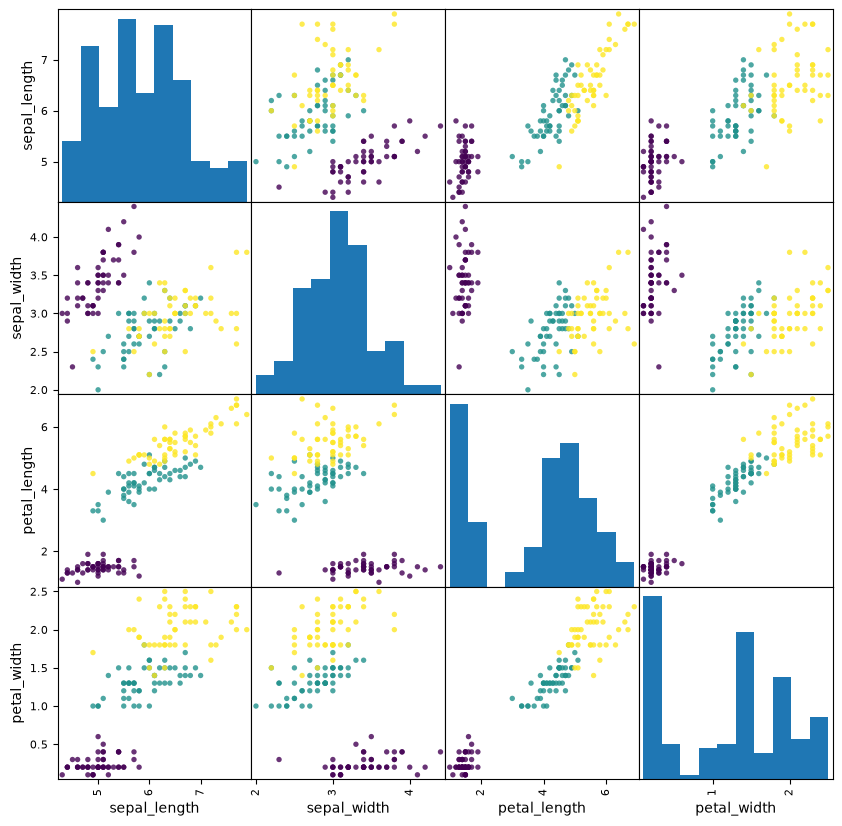

In [7]:
pd.plotting.scatter_matrix(df_dataset.iloc[:, 0:4], c=df_dataset['iris_class'], figsize=(10, 10), 
                           marker='.', hist_kwds={'bins': 10}, s=60, alpha=.8); 

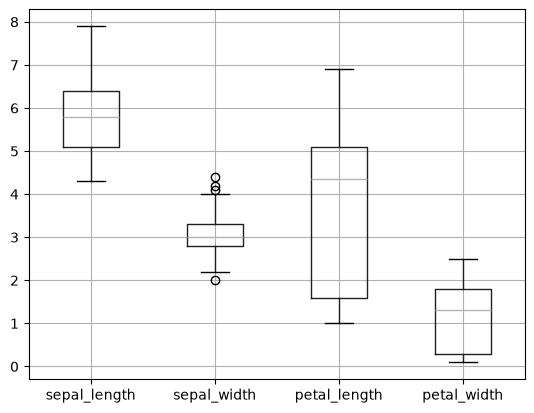

In [8]:
df_dataset.iloc[:, 0:4].boxplot();

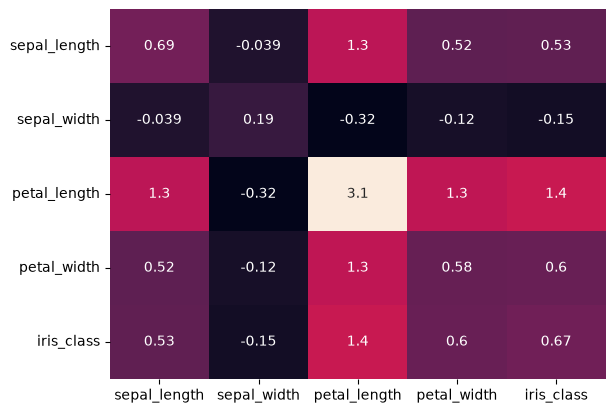

In [9]:
df_dataset_cov = df_dataset.cov()                                   
sns.heatmap(df_dataset_cov, annot = True, cbar = False);   

In [10]:
df_dataset = df_dataset.drop(['sepal_width'], axis=1)      
df_dataset.head(10)                                         

,sepal_length,petal_length,petal_width,iris_class
0,5.1,1.4,0.2,0
1,4.9,1.4,0.2,0
2,4.7,1.3,0.2,0
3,4.6,1.5,0.2,0
4,5.0,1.4,0.2,0
5,5.4,1.7,0.4,0
6,4.6,1.4,0.3,0
7,5.0,1.5,0.2,0
8,4.4,1.4,0.2,0
9,4.9,1.5,0.1,0


---

Step 3: Modeling

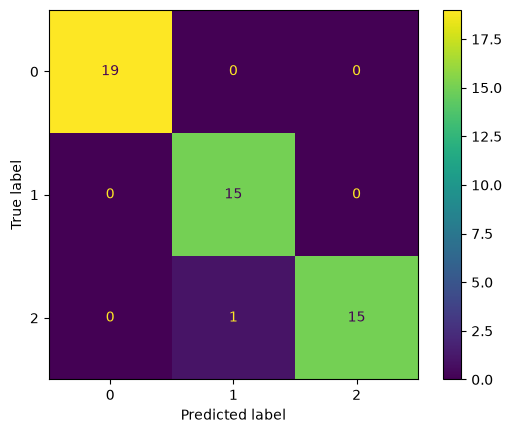

In [11]:
X = df_dataset.iloc[:, 0:3]
y = df_dataset.iloc[:, 3]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X_train, y_train)

tree.score(X_test, y_test)

y_pred = tree.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()

In [12]:
tree = DecisionTreeClassifier(max_depth=3)
tree.fit(X, y)
filename = "model_01.mod"
pickle.dump(tree, open(filename, 'wb'))

---

Step 4: Production

In [ ]:
# Prepare function for prediction model to production
tree_mod = pickle.load(open("model_01.mod", 'rb'))

def model_predic(sl, pl, pw):
    new_x = np.array([sl, pl, pw])
    new_x = new_x[np.newaxis, :]
    result = tree_mod.predict(new_x)
    return(result)

# Create User Interace
def bt_click():
    sl = float(scale_sl.get())
    pl = float(scale_pl.get())
    pw = float(scale_pw.get())
    answer = model_predic(sl, pl, pw)
    if answer[0] == 0:
        label_predict_1.config(text="setosa")
    elif answer[0] == 1:
        label_predict_1.config(text="versicolor")
    elif answer[0] == 2:
        label_predict_1.config(text="virginica")



window = Tk()
window.geometry('600x300')

scale_sl = Scale(from_=0, to=10, resolution=0.1, label="Sepal Length", showvalue=True, orient=VERTICAL, tickinterval=0.5, length=250)
scale_sl.grid(row=0, column=0)
scale_pl = Scale(from_=0, to=10, resolution=0.1, label="Petal Length", showvalue=True, orient=VERTICAL, tickinterval=0.5, length=250)
scale_pl.grid(row=0, column=2)
scale_pw = Scale(from_=0, to=10, resolution=0.1, label="Petal Width", showvalue=True, orient=VERTICAL, tickinterval=0.5, length=250)
scale_pw.grid(row=0, column=3)
label_predict_1 = Label(text="Predicted Class")
label_predict_1.grid(row=0, column=4)
bt_predict = Button(text="predict", command=bt_click)
bt_predict.grid(row=1, column=4)

window.mainloop()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


: 

---